<div style="background:#0D2137;padding:30px 34px;border-radius:12px">
  <p style="color:#66C2E0;font-size:13px;font-weight:700;letter-spacing:2px;margin:0">UNIVERSIDAD NACIONAL DE JULIACA · BIG DATA · 2026-2</p>
  <h1 style="color:white;margin:8px 0">EDA y calidad de datos: Elecciones Generales 2021</h1>
  <p style="color:#D6EAF8;font-size:16px;margin:0">Notebook modelo para exposición grupal · Evidencia, decisiones y límites</p>
</div>

**Integrantes:** Leibnihtz Abrahan Ayamamani Choque 

**Fecha de exposición:** 21-10-2026 - 23-10-2026

**Fuente:** Oficina Nacional de Procesos Electorales (ONPE), datos abiertos del Estado peruano.


## 0. Propósito, pregunta y alcance

Analizar cuántos ciudadanos estaban habilitados, cuántos participaron y qué proporción respaldó efectivamente a cada candidatura. Esto permitirá reflexionar sobre el nivel de representación electoral del resultado.

### Pregunta motivadora

**¿Qué proporción del electorado decide realmente quién gobierna el Perú y cómo influyen el ausentismo y los votos no efectivos?**

### Utilidad esperada

- Mostrar la diferencia entre electores habilitados, votantes y votos obtenidos por cada candidatura.
- Identificar el efecto del ausentismo y de los votos blancos, nulos e impugnados.
- Comparar el respaldo inicial de los dos finalistas con el padrón electoral completo.
- Promover una reflexión sobre la participación y el ejercicio político ciudadano.

### Alcance responsable

El análisis permite medir participación, ausentismo y distribución de votos. Sin embargo, el dataset no permite demostrar que estos resultados se deban a falta de cultura política, desinterés o desconocimiento. Esas explicaciones se plantearán como hipótesis, no como conclusiones.

### Ruta del trabajo

1. Reproducibilidad y fuente.
2. Comprensión, clasificación y diccionario.
3. Diagnóstico de calidad con reglas aplicables.
4. Preparación y feature engineering.
5. EDA univariado, bivariado y multivariado.
6. Interpretación de asociaciones y lectura territorial.
7. Diagnóstico, gobernanza mínima y cierre ejecutivo.

## 1. Entorno reproducible

In [1]:
# Aquí comprobamos el entorno que ejecuta el notebook antes de analizar los datos.
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

print("Python     :", sys.version.split()[0])
print("Ejecutable :", sys.executable)
print("Plataforma :", platform.platform())
print("pandas     :", pd.__version__)

ENTORNO_ESPERADO = "BigData20262"
if ENTORNO_ESPERADO.lower() in sys.executable.lower():
    print(f"Entorno     : ✓ {ENTORNO_ESPERADO}")
else:
    print(f"Entorno     : ⚠ seleccione el kernel Python ({ENTORNO_ESPERADO})")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 14})
SEED = 2021

Python     : 3.12.10
Ejecutable : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\BigData20262\Scripts\python.exe
Plataforma : Windows-11-10.0.26200-SP0
pandas     : 2.3.3
Entorno     : ✓ BigData20262


### Fuente, periodo, archivos y condiciones de uso

| Elemento | Descripción |
|---|---|
| Entidad publicadora | ONPE |
| Proceso | Elecciones Generales 2021, primera vuelta |
| Fecha electoral | 11 de abril de 2021 |
| Archivo de trabajo | `data/bronze/Elecciones2021.csv` |
| Formato | CSV, codificación Latin-1 |
| Granularidad | Mesa de votación, elección presidencial |
| Condición de uso | Datos abiertos; conservar atribución y trazabilidad de la fuente |

**Unidad de análisis:** una fila representa el resultado consolidado de **una mesa de votación** para la elección presidencial, localizada mediante UBIGEO/departamento/provincia/distrito. No representa a una persona ni a un voto individual.

La capa **Bronze** se trata como fuente inmutable. Las transformaciones ocurren en memoria y se documentan; no se sobrescribe el CSV original.

In [2]:
# Aquí buscamos la raíz del proyecto para evitar una ruta absoluta.
# dependiente de una sola computadora.
def encontrar_raiz(inicio=None):
    inicio = Path(inicio or Path.cwd()).resolve()
    candidatos = [inicio, *inicio.parents]
    for carpeta in candidatos:
        if (carpeta / "data" / "bronze" / "Elecciones2021.csv").exists():
            return carpeta
    raise FileNotFoundError(
        "No se encontró data/bronze/Elecciones2021.csv. "
        "Abra VS Code/Jupyter desde la carpeta raíz EDA."
    )

PROJECT_ROOT = encontrar_raiz()
DATA_PATH = PROJECT_ROOT / "data" / "bronze" / "Elecciones2021.csv"
print("Raíz del proyecto:", PROJECT_ROOT)
print("Fuente Bronze     :", DATA_PATH.relative_to(PROJECT_ROOT))

Raíz del proyecto: C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA
Fuente Bronze     : data\bronze\Elecciones2021.csv


In [3]:
# Latin-1 es necesario porque el archivo contiene caracteres que no están en UTF-8.
df_raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
print(f"Carga correcta: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
display(df_raw.head())

Carga correcta: 86,488 filas × 31 columnas

,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,TIPO_ELECCION,MESA_DE_VOTACION,DESCRIP_ESTADO_ACTA,TIPO_OBSERVACION,N_CVAS,N_ELEC_HABIL,...,VOTOS_P12,VOTOS_P13,VOTOS_P14,VOTOS_P15,VOTOS_P16,VOTOS_P17,VOTOS_P18,VOTOS_VB,VOTOS_VN,VOTOS_VI
0,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,PRESIDENCIAL,1,ACTA ELECTORAL NORMAL,NaN,181.0,300,...,1.0,22.0,NaN,3.0,26.0,1.0,7.0,25.0,17.0,NaN
1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,PRESIDENCIAL,2,ACTA ELECTORAL RESUELTA,R,192.0,300,...,NaN,13.0,NaN,1.0,23.0,1.0,11.0,30.0,19.0,NaN
2,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,PRESIDENCIAL,3,ACTA ELECTORAL NORMAL,NaN,198.0,300,...,2.0,22.0,NaN,5.0,30.0,1.0,14.0,16.0,11.0,NaN
3,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,PRESIDENCIAL,4,ACTA ELECTORAL NORMAL,NaN,215.0,300,...,NaN,22.0,1.0,4.0,34.0,NaN,7.0,36.0,14.0,NaN
4,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,PRESIDENCIAL,5,ACTA ELECTORAL NORMAL,NaN,213.0,300,...,NaN,24.0,NaN,7.0,23.0,NaN,16.0,13.0,13.0,NaN


## 2. Comprensión del dataset

In [4]:
# Aquí revisamos las evidencias mínimas de estructura: shape, info y describe.
print("shape:", df_raw.shape)
print("\ninfo():")
df_raw.info()

shape: (86488, 31)

info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86488 entries, 0 to 86487
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UBIGEO               86488 non-null  int64  
 1   DEPARTAMENTO         86488 non-null  object 
 2   PROVINCIA            86488 non-null  object 
 3   DISTRITO             86488 non-null  object 
 4   TIPO_ELECCION        86488 non-null  object 
 5   MESA_DE_VOTACION     86488 non-null  int64  
 6   DESCRIP_ESTADO_ACTA  86488 non-null  object 
 7   TIPO_OBSERVACION     4065 non-null   object 
 8   N_CVAS               85989 non-null  float64
 9   N_ELEC_HABIL         86488 non-null  int64  
 10  VOTOS_P1             65867 non-null  float64
 11  VOTOS_P2             42510 non-null  float64
 12  VOTOS_P3             72310 non-null  float64
 13  VOTOS_P4             39056 non-null  float64
 14  VOTOS_P5             80936 non-null  float64
 15  VOTOS_P6

In [5]:
columnas_clave = [
    "N_CVAS", "N_ELEC_HABIL", "VOTOS_VB", "VOTOS_VN", "VOTOS_VI"
]
display(df_raw[columnas_clave].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
N_CVAS,85989.0,206.00,46.00,0.0,190.0,218.0,236.0,300.0
N_ELEC_HABIL,86488.0,292.39,26.50,3.0,300.0,300.0,300.0,306.0
VOTOS_VB,84174.0,26.02,14.29,0.0,16.0,24.0,34.0,157.0
VOTOS_VN,84802.0,13.24,23.94,0.0,6.0,9.0,14.0,300.0
VOTOS_VI,2930.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0


**Interpretación breve de la evidencia inicial**

- Hay **86 488 mesas** y 31 campos; el archivo corresponde únicamente a `PRESIDENCIAL`.
- `N_ELEC_HABIL` está completo, pero `N_CVAS` falta en las mesas no instaladas. Esa ausencia tiene significado de negocio y no debe convertirse automáticamente en cero.
- Las columnas de partidos y votos especiales aparecen como `float` porque contienen celdas vacías. El tipo técnico no cambia su escala conceptual: son conteos discretos.
- Media y desviación no bastan para resumir conteos asimétricos; más adelante se contrastan con mediana, IQR y gráficos.

### 2.1 Clasificación de variables y diccionario relevante

In [6]:
diccionario = pd.DataFrame([
    ["UBIGEO", "Código geográfico del distrito", "Categórica nominal (identificador)", "6 dígitos", "Segmentación territorial"],
    ["DEPARTAMENTO", "Departamento o circunscripción continental del exterior", "Categórica nominal", "Catálogo geográfico", "Comparación territorial"],
    ["PROVINCIA", "Provincia donde se ubica la mesa", "Categórica nominal", "Catálogo geográfico", "Contexto territorial"],
    ["DISTRITO", "Distrito donde se ubica la mesa", "Categórica nominal", "Catálogo geográfico", "Desagregación local"],
    ["TIPO_ELECCION", "Tipo de elección del registro", "Categórica nominal", "PRESIDENCIAL", "Define el alcance"],
    ["MESA_DE_VOTACION", "Identificador de mesa", "Categórica nominal (identificador)", "Entero positivo", "Regla de unicidad"],
    ["DESCRIP_ESTADO_ACTA", "Estado de procesamiento del acta", "Categórica nominal", "Normal/resuelta/no instalada", "Interpreta ausencias"],
    ["TIPO_OBSERVACION", "Código de observación del acta", "Categórica nominal", "Catálogo ONPE o vacío", "Trazabilidad de incidencias"],
    ["N_CVAS", "Ciudadanos que votaron", "Numérica discreta", "0 a electores hábiles", "Participación"],
    ["N_ELEC_HABIL", "Electores habilitados en la mesa", "Numérica discreta", "Entero positivo", "Denominador poblacional"],
    ["VOTOS_P1…VOTOS_P18", "Votos por organización política", "Numérica discreta", "Conteo no negativo", "Voto válido"],
    ["VOTOS_VB", "Votos en blanco", "Numérica discreta", "Conteo no negativo", "Voto no efectivo"],
    ["VOTOS_VN", "Votos nulos", "Numérica discreta", "Conteo no negativo", "Voto no efectivo"],
    ["VOTOS_VI", "Votos impugnados", "Numérica discreta", "Conteo no negativo", "Voto no efectivo"],
], columns=["Columna", "Descripción", "Tipo o escala", "Unidad o dominio", "Importancia"])
display(diccionario)

,Columna,Descripción,Tipo o escala,Unidad o dominio,Importancia
0,UBIGEO,Código geográfico del distrito,Categórica nominal (identificador),6 dígitos,Segmentación territorial
1,DEPARTAMENTO,Departamento o circunscripción continental del...,Categórica nominal,Catálogo geográfico,Comparación territorial
2,PROVINCIA,Provincia donde se ubica la mesa,Categórica nominal,Catálogo geográfico,Contexto territorial
3,DISTRITO,Distrito donde se ubica la mesa,Categórica nominal,Catálogo geográfico,Desagregación local
4,TIPO_ELECCION,Tipo de elección del registro,Categórica nominal,PRESIDENCIAL,Define el alcance
5,MESA_DE_VOTACION,Identificador de mesa,Categórica nominal (identificador),Entero positivo,Regla de unicidad
6,DESCRIP_ESTADO_ACTA,Estado de procesamiento del acta,Categórica nominal,Normal/resuelta/no instalada,Interpreta ausencias
7,TIPO_OBSERVACION,Código de observación del acta,Categórica nominal,Catálogo ONPE o vacío,Trazabilidad de incidencias
8,N_CVAS,Ciudadanos que votaron,Numérica discreta,0 a electores hábiles,Participación
9,N_ELEC_HABIL,Electores habilitados en la mesa,Numérica discreta,Entero positivo,Denominador poblacional


> **Aquí distinguimos el tipo técnico del significado:** un número no siempre es una variable cuantitativa. `UBIGEO` y `MESA_DE_VOTACION` son códigos; promediarlos no tiene sentido. La escala conceptual decide el análisis, no solo el `dtype` de pandas.

## 3. Diagnóstico de calidad: reglas aplicables, no una lista forzada

En este bloque evaluamos cuatro dimensiones pertinentes a este archivo: **completitud, unicidad, validez y consistencia**. Exactitud requeriría contrastar cada acta contra una fuente primaria; oportunidad exigiría metadatos de actualización. Como esa evidencia no está en el CSV, no se asigna una falsa calificación.

In [7]:
# Normalizamos espacios solo en una copia de diagnóstico.
df = df_raw.copy()
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()

vote_party_cols = [c for c in df.columns if c.startswith("VOTOS_P")]
vote_special_cols = ["VOTOS_VB", "VOTOS_VN", "VOTOS_VI"]
vote_cols = vote_party_cols + vote_special_cols

perfil_nulos = (df.isna().mean().mul(100).sort_values(ascending=False)
                 .rename("pct_nulos").to_frame())
display(perfil_nulos.head(12).round(2))

,pct_nulos
VOTOS_VI,96.61
TIPO_OBSERVACION,95.30
VOTOS_P17,59.56
VOTOS_P4,54.84
VOTOS_P2,50.85
VOTOS_P14,45.37
VOTOS_P12,41.25
VOTOS_P10,28.10
VOTOS_P1,23.84
VOTOS_P15,16.49


### 3.1 Completitud con contexto

Aquí observamos que un porcentaje alto de nulos no implica por sí solo mala calidad:

- En una mesa instalada, una celda vacía de votos puede representar **cero votos** para esa opción si la suma de los demás componentes coincide con `N_CVAS`.
- En una mesa no instalada, los resultados están ausentes **por diseño**. Imputarlos como si la mesa hubiera operado distorsionaría la participación.

In [8]:
tabla_estado = pd.crosstab(
    df["DESCRIP_ESTADO_ACTA"],
    df["N_CVAS"].isna().map({False: "N_CVAS presente", True: "N_CVAS ausente"})
)
display(tabla_estado)

instalada = df["N_CVAS"].notna()
suma_componentes_cero_implicito = df[vote_cols].fillna(0).sum(axis=1)
coincide_total = suma_componentes_cero_implicito.eq(df["N_CVAS"])

print("Mesas con N_CVAS:", f"{instalada.sum():,}")
print("Mesas no instaladas / sin N_CVAS:", f"{(~instalada).sum():,}")
print("Mesas instaladas cuya suma de votos coincide con N_CVAS:",
      f"{(instalada & coincide_total).sum():,} de {instalada.sum():,}")

N_CVAS,N_CVAS ausente,N_CVAS presente
DESCRIP_ESTADO_ACTA,,
ACTA ELECTORAL NORMAL,0,81924
ACTA ELECTORAL RESUELTA,0,4065
MESA NO INSTALADA,499,0


Mesas con N_CVAS: 85,989


Mesas no instaladas / sin N_CVAS: 499
Mesas instaladas cuya suma de votos coincide con N_CVAS: 85,989 de 85,989


### 3.2 Unicidad, validez y consistencia

In [9]:
reglas = []

def agregar_regla(dimension, regla, mascara_aplica, mascara_cumple, impacto):
    aplica = pd.Series(mascara_aplica, index=df.index).fillna(False)
    cumple = pd.Series(mascara_cumple, index=df.index).fillna(False)
    n = int(aplica.sum())
    ok = int((aplica & cumple).sum())
    reglas.append({
        "Dimensión": dimension,
        "Regla": regla,
        "Registros evaluados": n,
        "Incumplimientos": n - ok,
        "% cumplimiento": 100 * ok / n if n else np.nan,
        "Impacto": impacto,
    })

# Unicidad: el identificador natural disponible es la mesa dentro del tipo de elección.
clave_unica = ~df.duplicated(["TIPO_ELECCION", "MESA_DE_VOTACION"], keep=False)
agregar_regla("Unicidad", "TIPO_ELECCION + MESA_DE_VOTACION es único",
              True, clave_unica, "Duplicados inflarían electores y votos")

# Validez: reglas de dominio observables en el CSV.
agregar_regla("Validez", "N_ELEC_HABIL > 0", True,
              df["N_ELEC_HABIL"].gt(0), "Un denominador no positivo invalida tasas")
agregar_regla("Validez", "Conteos de votos no negativos", instalada,
              df[vote_cols].fillna(0).ge(0).all(axis=1), "Negativos distorsionan totales")
agregar_regla("Validez", "UBIGEO puede expresarse con 6 dígitos", True,
              df["UBIGEO"].astype("string").str.zfill(6).str.fullmatch(r"\d{6}"),
              "Códigos inválidos impiden agregación territorial")

# Consistencia: relaciones entre campos.
agregar_regla("Consistencia", "0 ≤ N_CVAS ≤ N_ELEC_HABIL", instalada,
              df["N_CVAS"].ge(0) & df["N_CVAS"].le(df["N_ELEC_HABIL"]),
              "Afecta participación y ausentismo")
agregar_regla("Consistencia", "Suma de componentes de voto = N_CVAS", instalada,
              coincide_total, "Una diferencia altera votos válidos/no efectivos")
agregar_regla("Completitud", "N_CVAS presente cuando la mesa fue instalada", instalada,
              df["N_CVAS"].notna(), "Sin total de votantes no se calculan tasas")

reporte_calidad = pd.DataFrame(reglas)
reporte_calidad["% cumplimiento"] = reporte_calidad["% cumplimiento"].round(3)
display(reporte_calidad)

,Dimensión,Regla,Registros evaluados,Incumplimientos,% cumplimiento,Impacto
0,Unicidad,TIPO_ELECCION + MESA_DE_VOTACION es único,86488,0,100.0,Duplicados inflarían electores y votos
1,Validez,N_ELEC_HABIL > 0,86488,0,100.0,Un denominador no positivo invalida tasas
2,Validez,Conteos de votos no negativos,85989,0,100.0,Negativos distorsionan totales
3,Validez,UBIGEO puede expresarse con 6 dígitos,86488,0,100.0,Códigos inválidos impiden agregación territorial
4,Consistencia,0 ≤ N_CVAS ≤ N_ELEC_HABIL,85989,0,100.0,Afecta participación y ausentismo
5,Consistencia,Suma de componentes de voto = N_CVAS,85989,0,100.0,Una diferencia altera votos válidos/no efectivos
6,Completitud,N_CVAS presente cuando la mesa fue instalada,85989,0,100.0,Sin total de votantes no se calculan tasas


### Decisión de tratamiento

Aquí tomamos tres decisiones basadas en el significado de los datos:

1. Se excluyen de las tasas las mesas no instaladas porque no tuvieron proceso de votación; **no son “ceros”**.
2. En mesas instaladas, los vacíos de componentes de voto se interpretan como cero únicamente después de verificar que la suma completa coincide con `N_CVAS`.
3. No se elimina ninguna fila por “outlier” solo por ser extrema. Primero se comprueba validez de dominio y se conserva trazabilidad.

## 4. Preparación y feature engineering

In [10]:
# Conservamos las mesas con total de votantes y coherencia contable.
df_clean = df.loc[instalada & coincide_total].copy()
df_clean[vote_cols] = df_clean[vote_cols].fillna(0).astype("int64")

# Feature engineering original, conservado y reforzado con denominadores seguros.
df_clean["votos_validos"] = df_clean[vote_party_cols].sum(axis=1)
df_clean["votos_no_efectivos"] = df_clean[vote_special_cols].sum(axis=1)
df_clean["ausentes"] = df_clean["N_ELEC_HABIL"] - df_clean["N_CVAS"]
df_clean["participacion"] = df_clean["N_CVAS"].div(df_clean["N_ELEC_HABIL"])
df_clean["tasa_voto_no_efectivo"] = (
    df_clean["votos_no_efectivos"].div(df_clean["N_CVAS"].replace(0, np.nan))
)
df_clean["poder_perdido"] = df_clean["ausentes"] + df_clean["votos_no_efectivos"]
df_clean["tasa_poder_perdido"] = df_clean["poder_perdido"].div(df_clean["N_ELEC_HABIL"])
df_clean["tiene_observacion"] = df_clean["TIPO_OBSERVACION"].notna()

print(f"Filas Bronze : {len(df):,}")
print(f"Filas análisis: {len(df_clean):,}")
print(f"Excluidas con justificación: {len(df)-len(df_clean):,}")
display(df_clean[["MESA_DE_VOTACION", "participacion", "tasa_voto_no_efectivo",
                  "tasa_poder_perdido"]].head())

Filas Bronze : 86,488
Filas análisis: 85,989
Excluidas con justificación: 499


,MESA_DE_VOTACION,participacion,tasa_voto_no_efectivo,tasa_poder_perdido
0,1,0.603333,0.232044,0.536667
1,2,0.640000,0.255208,0.523333
2,3,0.660000,0.136364,0.430000
3,4,0.716667,0.232558,0.450000
4,5,0.710000,0.122066,0.376667


### Definición de métricas

\[
participación=\frac{N\_CVAS}{N\_ELEC\_HABIL}
\]

\[
tasa\ de\ voto\ no\ efectivo=\frac{VOTOS\_VB+VOTOS\_VN+VOTOS\_VI}{N\_CVAS}
\]

\[
tasa\ de\ poder\ electoral\ perdido=\frac{ausentes+votos\ blancos+nulos+impugnados}{N\_ELEC\_HABIL}
\]

“Poder perdido” es una **métrica analítica construida**, no una categoría oficial de ONPE ni un juicio sobre la intención del elector.

## 5. Análisis exploratorio de datos

Aquí avanzamos de lo simple a lo integrado: primero estudiamos una variable, luego relacionamos dos y finalmente combinamos varias para construir una lectura territorial.

### 5.1 Análisis univariado: una variable a la vez

Aquí usamos las herramientas vistas en clase:

| Tipo de variable | Resumen | Gráfico |
|---|---|---|
| Categórica | frecuencia y porcentaje | barras |
| Numérica | media, mediana, mínimo y máximo | histograma |

En tasas electorales damos importancia a la **mediana**, porque valores territoriales o mesas extremas pueden alejar la media.

,estado,mesas,porcentaje
0,ACTA ELECTORAL NORMAL,81924,94.72
1,ACTA ELECTORAL RESUELTA,4065,4.70
2,MESA NO INSTALADA,499,0.58


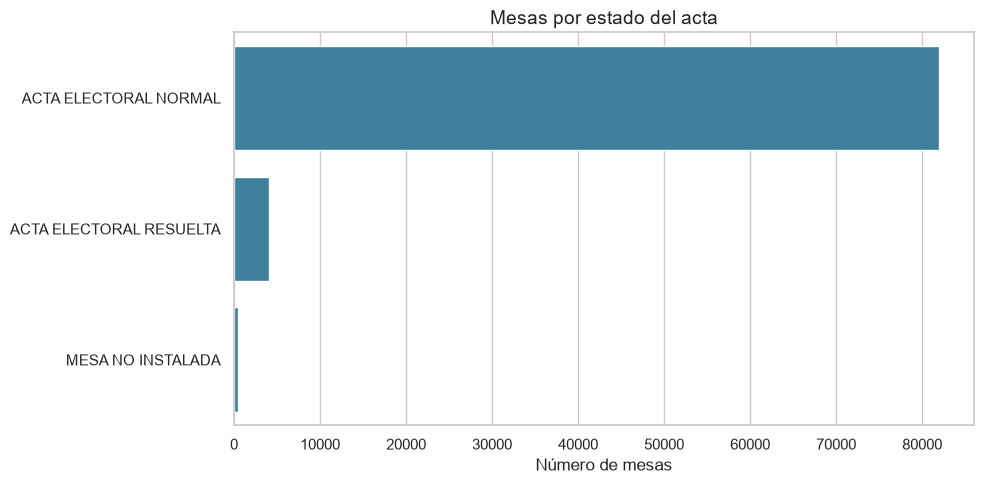

In [11]:
# Categórica: estado de acta.
estado = (df["DESCRIP_ESTADO_ACTA"].value_counts(dropna=False)
          .rename_axis("estado").reset_index(name="mesas"))
estado["porcentaje"] = 100 * estado["mesas"] / len(df)
display(estado.round(2))

ax = sns.barplot(data=estado, y="estado", x="mesas", color="#2E86AB")
ax.set(title="Mesas por estado del acta", xlabel="Número de mesas", ylabel="")
plt.tight_layout()
plt.show()

,participacion,tasa_voto_no_efectivo,tasa_poder_perdido
n,85989.0000,85988.0000,85989.0000
media,0.7048,0.1935,0.4278
mediana,0.7400,0.1652,0.3900
desv_est,0.1435,0.1287,0.1584
mínimo,0.0000,0.0000,0.0208
Q1,0.6567,0.1164,0.3200
Q3,0.7967,0.2406,0.5036
máximo,1.0000,1.0000,1.0000


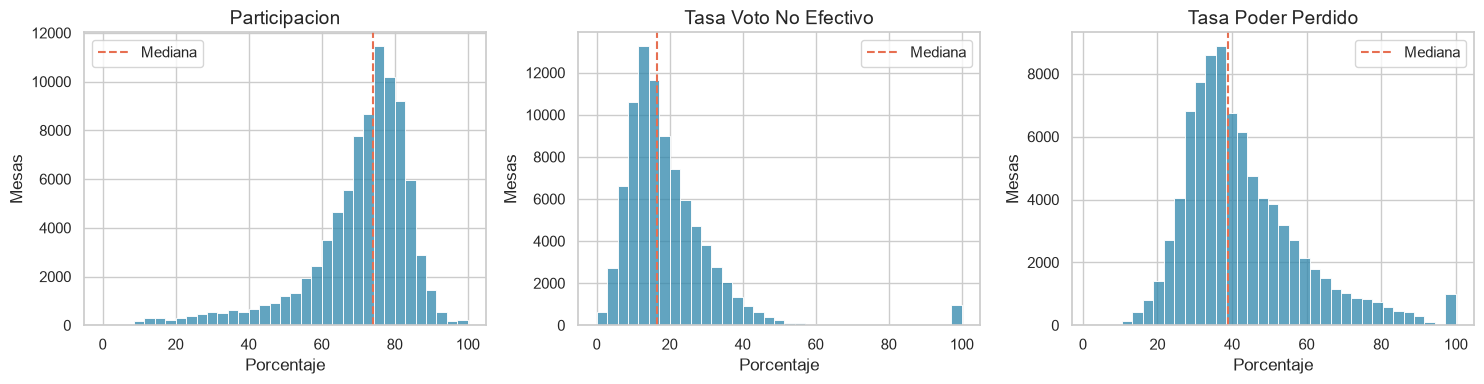

In [12]:
# Numéricas derivadas: mediana e IQR son esenciales si hay asimetría.
metricas = ["participacion", "tasa_voto_no_efectivo", "tasa_poder_perdido"]
resumen_robusto = df_clean[metricas].agg(
    ["count", "mean", "median", "std", "min", lambda s: s.quantile(.25),
     lambda s: s.quantile(.75), "max"]
)
resumen_robusto.index = ["n", "media", "mediana", "desv_est", "mínimo", "Q1", "Q3", "máximo"]
display(resumen_robusto.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, metricas):
    sns.histplot(df_clean[col].dropna() * 100, bins=35, ax=ax, color="#2E86AB")
    ax.axvline(df_clean[col].median() * 100, color="#E76F51", ls="--", label="Mediana")
    ax.set(title=col.replace("_", " ").title(), xlabel="Porcentaje", ylabel="Mesas")
    ax.legend()
plt.tight_layout()
plt.show()

### 5.2 Análisis bivariado: relación entre dos variables

Aquí relacionamos **participación**, **voto no efectivo** y **poder electoral perdido**. Como son tasas y sus histogramas no son simétricos, utilizamos **Spearman**.

> Spearman permite observar si dos variables tienden a aumentar o disminuir juntas sin exigir una distribución normal. Una correlación describe asociación; no demuestra causalidad.

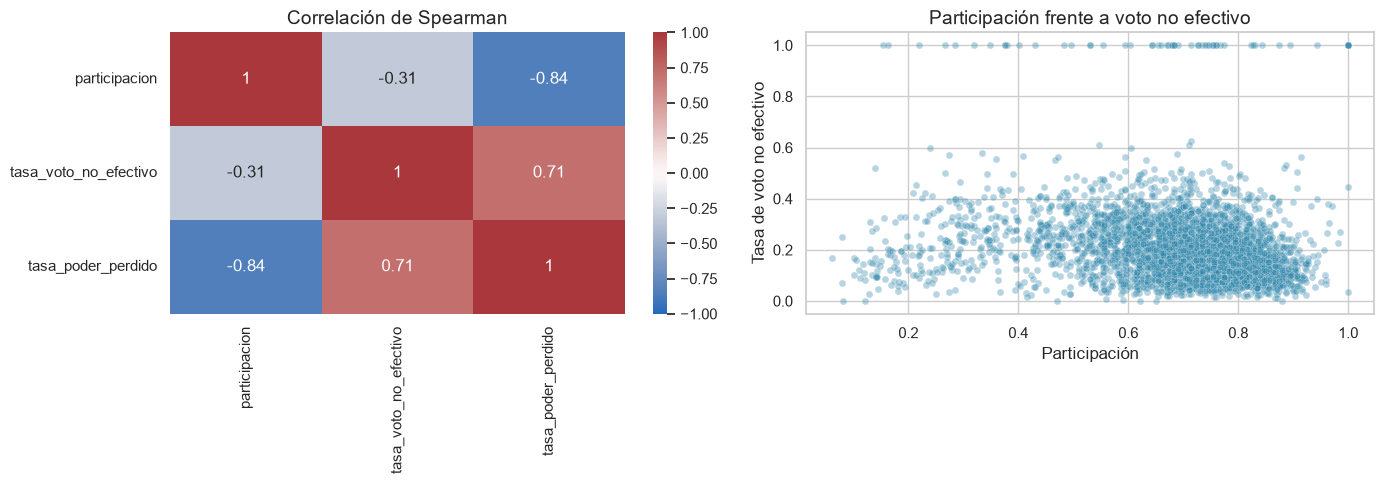

In [13]:
# Correlación sencilla entre las métricas construidas.
metricas_bivariadas = [
    "participacion",
    "tasa_voto_no_efectivo",
    "tasa_poder_perdido",
]
corr_spearman = df_clean[metricas_bivariadas].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr_spearman, annot=True, cmap="vlag", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlación de Spearman")

muestra_grafica = df_clean.sample(min(5000, len(df_clean)), random_state=SEED)
sns.scatterplot(data=muestra_grafica,
                x="participacion", y="tasa_voto_no_efectivo",
                alpha=.35, s=25, color="#2E86AB", ax=axes[1])
axes[1].set_title("Participación frente a voto no efectivo")
axes[1].set_xlabel("Participación")
axes[1].set_ylabel("Tasa de voto no efectivo")
plt.tight_layout()
plt.show()

**Aquí leemos la asociación:** el signo indica si la relación va en la misma dirección o en dirección contraria; la cercanía a 1 o -1 indica mayor intensidad. El resultado debe interpretarse junto con el gráfico y el contexto electoral.

### 5.3 Análisis multivariado: lectura territorial

Aquí combinamos departamento, participación, voto no efectivo y tamaño del padrón. El objetivo es reconocer perfiles territoriales, no explicar sus causas.

In [14]:
# Las tasas departamentales se calculan como razón de sumas, no como promedio simple
# de porcentajes de mesas. Así cada mesa aporta según su número de electores.
depto = (df_clean.groupby("DEPARTAMENTO", as_index=False)
         .agg(mesas=("MESA_DE_VOTACION", "nunique"),
              electores_habiles=("N_ELEC_HABIL", "sum"),
              votaron=("N_CVAS", "sum"),
              ausentes=("ausentes", "sum"),
              votos_no_efectivos=("votos_no_efectivos", "sum"),
              votos_validos=("votos_validos", "sum")))
depto["participacion"] = depto["votaron"] / depto["electores_habiles"]
depto["tasa_voto_no_efectivo"] = depto["votos_no_efectivos"] / depto["votaron"]
depto["tasa_poder_perdido"] = (depto["ausentes"] + depto["votos_no_efectivos"]) / depto["electores_habiles"]

# El campo DEPARTAMENTO también contiene circunscripciones del exterior.
exterior = {"AFRICA", "AMERICA", "ASIA", "EUROPA", "OCEANIA"}
depto["ambito"] = np.where(depto["DEPARTAMENTO"].isin(exterior), "Exterior", "Perú")
depto_peru = depto.query("ambito == 'Perú'").copy()
depto_exterior = depto.query("ambito == 'Exterior'").copy()

print("Departamentos del Perú (incluye Callao):", len(depto_peru))
print("Circunscripciones del exterior:", len(depto_exterior))
display(depto_peru.sort_values("tasa_poder_perdido", ascending=False).head(10).round(4))
display(depto_exterior.sort_values("tasa_poder_perdido", ascending=False).round(4))

Departamentos del Perú (incluye Callao): 25
Circunscripciones del exterior: 5


,DEPARTAMENTO,mesas,electores_habiles,votaron,ausentes,votos_no_efectivos,votos_validos,participacion,tasa_voto_no_efectivo,tasa_poder_perdido,ambito
1,AMAZONAS,1105,306186,184057.0,122129.0,51858,132199,0.6011,0.2817,0.5682,Perú
19,LORETO,2392,699964,426483.0,273481.0,112375,314108,0.6093,0.2635,0.5513,Perú
8,CAJAMARCA,3827,1102947,690647.0,412300.0,173185,517462,0.6262,0.2508,0.5308,Perú
29,UCAYALI,1317,389889,258403.0,131486.0,70033,188370,0.6628,0.2710,0.5169,Perú
12,HUANCAVELICA,1094,299843,202550.0,97293.0,55163,147387,0.6755,0.2723,0.5085,Perú
26,SAN MARTIN,2188,636330,440129.0,196201.0,126659,313470,0.6917,0.2878,0.5074,Perú
23,PASCO,695,200682,127727.0,72955.0,27731,99996,0.6365,0.2171,0.5017,Perú
24,PIURA,4811,1396448,932186.0,464262.0,231241,700945,0.6675,0.2481,0.4981,Perú
13,HUANUCO,2051,586411,400380.0,186031.0,105157,295223,0.6828,0.2626,0.4966,Perú
4,APURIMAC,1125,316000,219260.0,96740.0,53074,166186,0.6939,0.2421,0.4741,Perú


,DEPARTAMENTO,mesas,electores_habiles,votaron,ausentes,votos_no_efectivos,votos_validos,participacion,tasa_voto_no_efectivo,tasa_poder_perdido,ambito
0,AFRICA,4,295,49.0,246.0,31,18,0.1661,0.6327,0.9390,Exterior
6,ASIA,143,36870,7330.0,29540.0,1530,5800,0.1988,0.2087,0.8427,Exterior
2,AMERICA,1759,515406,124847.0,390559.0,39491,85356,0.2422,0.3163,0.8344,Exterior
11,EUROPA,1012,291798,93595.0,198203.0,24941,68654,0.3208,0.2665,0.7647,Exterior
22,OCEANIA,24,6222,2081.0,4141.0,336,1745,0.3345,0.1615,0.7195,Exterior


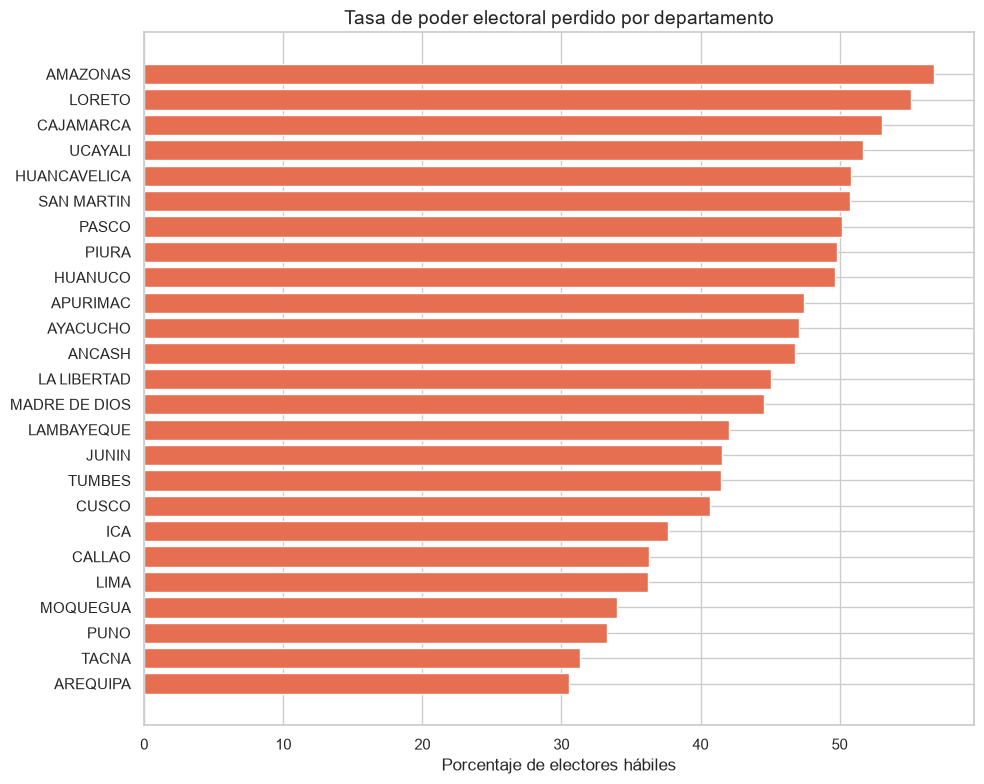

In [15]:
orden = depto_peru.sort_values("tasa_poder_perdido")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(orden["DEPARTAMENTO"], orden["tasa_poder_perdido"] * 100, color="#E76F51")
ax.set(title="Tasa de poder electoral perdido por departamento",
       xlabel="Porcentaje de electores hábiles", ylabel="")
plt.tight_layout()
plt.show()

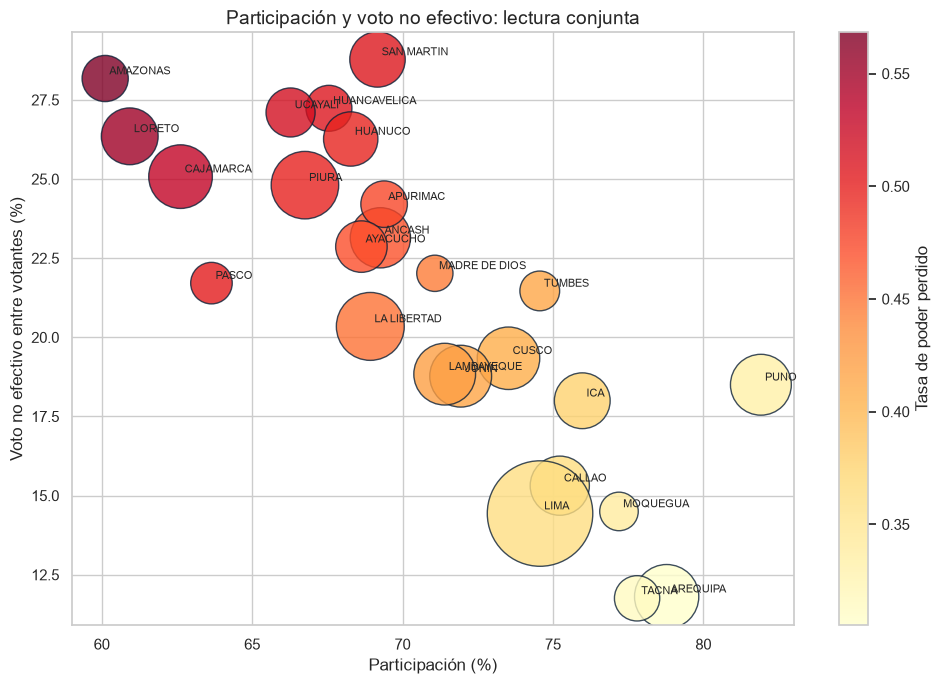

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(depto_peru["participacion"] * 100,
                depto_peru["tasa_voto_no_efectivo"] * 100,
                s=np.sqrt(depto_peru["electores_habiles"]) * 2,
                c=depto_peru["tasa_poder_perdido"], cmap="YlOrRd",
                alpha=.8, edgecolor="#0D2137")
for _, r in depto_peru.iterrows():
    ax.annotate(r["DEPARTAMENTO"],
                (r["participacion"] * 100, r["tasa_voto_no_efectivo"] * 100),
                fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="Tasa de poder perdido")
ax.set(title="Participación y voto no efectivo: lectura conjunta",
       xlabel="Participación (%)", ylabel="Voto no efectivo entre votantes (%)")
plt.tight_layout()
plt.show()

**En este gráfico observamos:** posición horizontal = participación; posición vertical = voto no efectivo; tamaño = electores hábiles; color = tasa de poder perdido. La visualización ayuda a detectar perfiles territoriales, pero no explica sus causas.

## 6. ¿Quiénes eligieron a los finalistas?

En una primera vuelta todos los votos válidos influyen en el orden de las candidaturas. Sin embargo, solo las dos con mayor votación pasan a la segunda vuelta. Aquí distinguimos cuatro grupos respecto al padrón completo:

1. electores que respaldaron a los dos finalistas;
2. electores que votaron por otras candidaturas;
3. votos blancos, nulos o impugnados;
4. electores ausentes.

Esta clasificación mide **respaldo electoral inicial**. No demuestra por qué una persona se ausentó o eligió determinada opción.

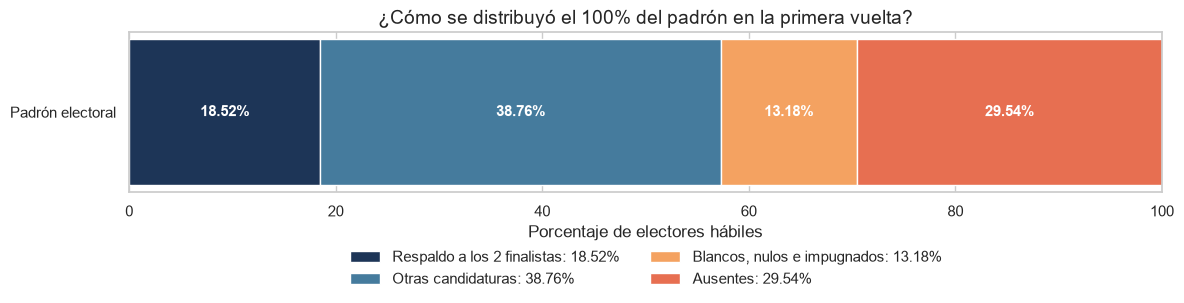

In [17]:
# Ranking dinámico: no escribimos de antemano qué columnas quedaron primero y segundo.
votos_partidos = df_clean[vote_party_cols].sum().sort_values(ascending=False)
primer_puesto, segundo_puesto = votos_partidos.index[:2]
votos_primero = int(votos_partidos.iloc[0])
votos_segundo = int(votos_partidos.iloc[1])
votos_finalistas = votos_primero + votos_segundo

total_hab = int(df_clean["N_ELEC_HABIL"].sum())
total_vot = int(df_clean["N_CVAS"].sum())
total_aus = int(df_clean["ausentes"].sum())
total_vne = int(df_clean["votos_no_efectivos"].sum())
total_validos = int(df_clean["votos_validos"].sum())
votos_otras_candidaturas = total_validos - votos_finalistas

segmentos_padron = pd.DataFrame({
    "grupo": [
        "Respaldo a los 2 finalistas",
        "Otras candidaturas",
        "Blancos, nulos e impugnados",
        "Ausentes",
    ],
    "electores": [votos_finalistas, votos_otras_candidaturas, total_vne, total_aus],
})
segmentos_padron["porcentaje"] = 100 * segmentos_padron["electores"] / total_hab

colores = ["#1D3557", "#457B9D", "#F4A261", "#E76F51"]
fig, ax = plt.subplots(figsize=(12, 3.5))
left = 0
for (_, fila), color in zip(segmentos_padron.iterrows(), colores):
    ancho = fila["porcentaje"]
    ax.barh(["Padrón electoral"], [ancho], left=left, color=color,
            label=f"{fila['grupo']}: {ancho:.2f}%")
    ax.text(left + ancho / 2, 0, f"{ancho:.2f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=11)
    left += ancho

ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de electores hábiles")
ax.set_title("¿Cómo se distribuyó el 100% del padrón en la primera vuelta?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### Lectura política responsable

Aquí interpretamos el resultado sin favorecer a ninguna candidatura. Las dos candidaturas clasificadas reunieron conjuntamente **18.52% del padrón electoral** en la primera vuelta. Por tanto, **81.48% de los electores habilitados no respaldó inicialmente a ninguno de los dos finalistas**: votó por otra candidatura, emitió un voto no efectivo o no participó.

Esto evidencia una representación inicial fragmentada y permite plantear una pregunta institucional, sin favorecer a ninguna candidatura:

> **¿Son suficientes los mecanismos electorales actuales para construir una presidencia ampliamente representativa cuando los finalistas parten con un respaldo reducido respecto al padrón total?**

La segunda vuelta existe precisamente para que los finalistas busquen una mayoría entre los votos válidos. Por eso, no afirmamos que el presidente haya sido elegido únicamente por el 18.52%; afirmamos que **los dos finalistas surgieron inicialmente del respaldo conjunto del 18.52% del padrón**.

## 7. Diagnóstico final de calidad y acciones

In [18]:
diagnostico_final = pd.DataFrame([
    {
        "Problema / condición": "499 mesas no instaladas sin resultados",
        "Cuantificación": f"{(~instalada).sum():,} ({(~instalada).mean():.2%} del archivo)",
        "Impacto": "Si se imputan como cero, se confunde ausencia estructural con cero participación.",
        "Acción sugerida": "Excluir de tasas operativas; conservar y reportar como categoría separada.",
        "Responsable sugerido": "Analista / data steward electoral",
    },
    {
        "Problema / condición": "Ceros codificados como vacíos en componentes de voto",
        "Cuantificación": f"{df[vote_cols].isna().any(axis=1).sum():,} filas con al menos un vacío",
        "Impacto": "Sin regla de dominio, sumas y tipos numéricos pueden quedar incompletos.",
        "Acción sugerida": "Recodificar a cero solo en mesas instaladas y validar suma = N_CVAS.",
        "Responsable sugerido": "Analista; documentar con propietario de la fuente",
    },
    {
        "Problema / condición": "TIPO_OBSERVACION mayormente vacío",
        "Cuantificación": f"{df['TIPO_OBSERVACION'].isna().mean():.2%} de valores ausentes",
        "Impacto": "No debe interpretarse automáticamente como error; limita análisis de incidencias sin catálogo.",
        "Acción sugerida": "Solicitar catálogo/metadatos y distinguir 'sin observación' de 'dato desconocido'.",
        "Responsable sugerido": "Propietario ONPE / data steward",
    },
])
display(diagnostico_final)

,Problema / condición,Cuantificación,Impacto,Acción sugerida,Responsable sugerido
0,499 mesas no instaladas sin resultados,499 (0.58% del archivo),"Si se imputan como cero, se confunde ausencia ...",Excluir de tasas operativas; conservar y repor...,Analista / data steward electoral
1,Ceros codificados como vacíos en componentes d...,"83,558 filas con al menos un vacío","Sin regla de dominio, sumas y tipos numéricos ...",Recodificar a cero solo en mesas instaladas y ...,Analista; documentar con propietario de la fuente
2,TIPO_OBSERVACION mayormente vacío,95.30% de valores ausentes,No debe interpretarse automáticamente como err...,Solicitar catálogo/metadatos y distinguir 'sin...,Propietario ONPE / data steward


## 8. Gestión y gobierno de datos, en la medida necesaria

Aquí incorporamos únicamente el gobierno necesario para el análisis. No se fuerza un programa completo de gobierno. Para que este análisis sea repetible y auditable bastan controles concretos:

| Control | Aplicación en este proyecto |
|---|---|
| Propietario de datos | ONPE publica y define el significado oficial de los campos |
| Data steward | Custodia diccionario, catálogos y reglas de calidad |
| Analista | No modifica Bronze; versiona código y documenta filtros/derivaciones |
| Linaje | ONPE → CSV Bronze → reglas de calidad → `df_clean` → métricas y gráficos |
| Metadatos | Fuente, fecha electoral, unidad de análisis, codificación y definiciones |
| Ética | Resultados agregados; no atribuir motivos individuales ni causalidad |

**Regla de oro:** toda cifra presentada debe poder rastrearse hasta una columna fuente, una transformación explícita y un denominador definido.

## 9. Cierre visual: del padrón a los finalistas

Aquí comparamos cada resultado directamente con el universo de electores habilitados, en lugar de cerrar con una lista de cifras. cada resultado directamente con el universo de electores habilitados.

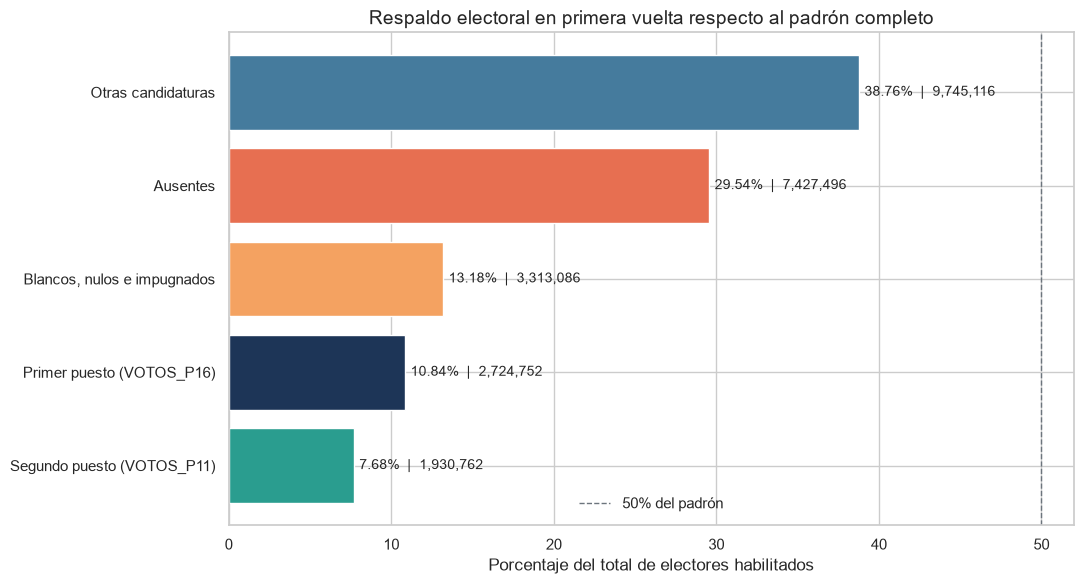

Los dos finalistas reunieron 4,655,514 votos: 18.52% del padrón.
El 81.48% restante no respaldó inicialmente a ninguno de los dos finalistas.


In [19]:
# Barras comparables: todas usan el padrón electoral como denominador.
resumen_padron = pd.DataFrame({
    "grupo": [
        f"Primer puesto ({primer_puesto})",
        f"Segundo puesto ({segundo_puesto})",
        "Otras candidaturas",
        "Blancos, nulos e impugnados",
        "Ausentes",
    ],
    "electores": [votos_primero, votos_segundo, votos_otras_candidaturas, total_vne, total_aus],
})
resumen_padron["porcentaje_padron"] = 100 * resumen_padron["electores"] / total_hab

orden = resumen_padron.sort_values("porcentaje_padron")
palette = {
    f"Primer puesto ({primer_puesto})": "#1D3557",
    f"Segundo puesto ({segundo_puesto})": "#2A9D8F",
    "Otras candidaturas": "#457B9D",
    "Blancos, nulos e impugnados": "#F4A261",
    "Ausentes": "#E76F51",
}

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(orden["grupo"], orden["porcentaje_padron"],
               color=[palette[g] for g in orden["grupo"]])
for bar, pct, n in zip(bars, orden["porcentaje_padron"], orden["electores"]):
    ax.text(pct + 0.35, bar.get_y() + bar.get_height()/2,
            f"{pct:.2f}%  |  {n:,.0f}", va="center", fontsize=10)

ax.axvline(50, color="#6C757D", linestyle="--", linewidth=1,
           label="50% del padrón")
ax.set_xlim(0, max(52, orden["porcentaje_padron"].max() + 8))
ax.set_xlabel("Porcentaje del total de electores habilitados")
ax.set_ylabel("")
ax.set_title("Respaldo electoral en primera vuelta respecto al padrón completo")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Los dos finalistas reunieron {votos_finalistas:,.0f} votos: "
      f"{votos_finalistas/total_hab:.2%} del padrón.")
print(f"El {1-votos_finalistas/total_hab:.2%} restante no respaldó inicialmente "
      "a ninguno de los dos finalistas.")

### Aquí cerramos con hallazgo, evidencia, interpretación y limitación

**Hallazgo.** En la primera vuelta, los dos finalistas concentraron conjuntamente 4 655 514 votos, equivalentes al **18.52% de los electores habilitados**. El **81.48% restante** votó por otras candidaturas, emitió votos blancos/nulos/impugnados o no participó.  
**Evidencia.** Todos los porcentajes del gráfico utilizan como denominador común los 25 141 212 electores habilitados de las mesas analizadas.  
**Interpretación.** El resultado muestra una representación inicial fragmentada y abre una reflexión sobre participación ciudadana, formación política y mecanismos de representación.  
**Limitación.** El CSV electoral cuantifica conductas, pero no explica sus motivos. La falta de cultura política, el desinterés o el desconocimiento son hipótesis que deben investigarse mediante encuestas u otras fuentes. La segunda vuelta constituye otra etapa del proceso y requiere analizar su propio dataset antes de concluir quién eligió finalmente al presidente.

### Preparación para la evaluación ampliada

Los 16 puntos restantes todavía no tienen una rúbrica oficial. Este notebook deja evidencias alineadas con los temas trabajados en las PPT: entorno reproducible, fuente y tipos de datos, calidad, feature engineering, EDA univariado/bivariado/multivariado, visualización, interpretación responsable y gobierno básico de datos. **Esta lista orienta el trabajo, pero no asigna puntajes.**

### Evidencias que presentamos para los 4 puntos de la rúbrica

- [ ] Aquí presentamos el tema, la pregunta y su utilidad.
- [ ] Aquí explicamos fuente, periodo, tamaño, archivo y unidad de análisis.
- [ ] Aquí mostramos `head()`, `shape`, `info()`, `describe()` e interpretamos los resultados.
- [ ] Aquí explicamos el diccionario de las columnas relevantes.
- [ ] Aquí justificamos reglas de completitud, unicidad, validez y consistencia.
- [ ] Aquí cuantificamos condiciones de calidad, impacto, acción y responsable.
- [ ] Aquí distinguimos votos válidos, votos no efectivos y respaldo a los finalistas.
- [ ] Aquí evitamos atribuir causas o afirmar que la primera vuelta eligió al presidente.

## 10. Preguntas de afianzamiento

1. ¿Por qué una mesa no instalada no debe convertirse automáticamente en una mesa con cero votantes?
2. ¿Qué evidencia permite interpretar ciertos vacíos en columnas de votos como ceros implícitos?
3. ¿Por qué se eligió Spearman y no Pearson para las tasas a nivel mesa?
4. ¿Qué cambia si se promedian tasas por mesa en vez de calcular la razón de sumas por departamento?
5. ¿Qué fuente adicional permitiría investigar una hipótesis explicativa sin afirmar causalidad prematuramente?

---
**Curso:** Big Data · EPISS · Universidad Nacional de Juliaca  
**Docente:** Leibnihtz Abrahan Ayamamani Choque  
**Caso:** Resultados electorales ONPE 2021 · Notebook modelo de EDA y calidad de datos